# HazeGuard-MY — Damage-cost tests

Tests and graphs for `pipeline/04_policy.py`. Run top to bottom (**Kernel → Restart & Run All**).
Every check prints `PASS`/`FAIL`, and the last cell lists them all and fails if any check failed.

**Method (per sector, per state, per day):**
`Damage = Daily Economic Value × Loss Rate (API band) × Share of activity affected × Days`

| Section | What it does | Brief step |
|---|---|---|
| 1 | Setup | |
| 2 | Load the data, view it | |
| 3 | Sector baselines: daily economic value by sector and state | 1–3 |
| 4 | Loss rates by haze severity, and the worked example | 4–5 |
| 5 | Haze data checks + graphs | |
| 6 | Run the model | |
| 7 | Output checks | |
| 8 | Results by sector and state | 6 |
| 9 | 72-hour scenarios: best / expected / worst | 7 |
| 10 | Behaviour checks (clean air, dose–response) | |
| 11 | Uncertainty (Monte Carlo) | |
| 12 | Sensitivity (tornado) | |
| 13 | Backtest vs mock truth | |
| 14 | Realism check vs published estimates | |
| 15 | Test summary | |

> **State GDP is real** (DOSM 2025). Sector shares, tourism splits and most loss rates are approximations with
> sources listed; haze history is synthetic unless `data/raw/pm25_daily_openmeteo.csv` exists.
> School closures, cloud seeding and mortality are **reported separately, not added to the total**
> (they overlap with sector losses). Mortality is off: haze is treated as non-fatal.

Setup: `pip install -r pipeline/requirements.txt`, then `jupyter notebook tests/04_damage_tests.ipynb`.

## 1. Setup

In [1]:
import importlib.util
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import display

# Find the repo root whether the notebook runs from tests/ or the root
ROOT = Path.cwd() if (Path.cwd() / "pipeline").exists() else Path.cwd().parent
spec = importlib.util.spec_from_file_location("policy", ROOT / "pipeline" / "04_policy.py")
policy = importlib.util.module_from_spec(spec)
spec.loader.exec_module(policy)

# Chart style: light surface, recessive grid, fixed colours
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
OTHER = "#c3c2b7"
BAND_COLOURS = {"good": "#0ca30c", "moderate": "#fab219", "unhealthy": "#ec835a",
                "very_unhealthy": "#d03b3b", "hazardous": "#7a1f1f"}
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": OTHER,
    "axes.labelcolor": INK, "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110,
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 9.5, "legend.frameon": False,
})
rm_m = mtick.FuncFormatter(lambda v, _: f"RM {v/1e6:,.0f} m")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

RESULTS = []
def check(name, condition, detail=""):
    """Record and print one test result."""
    ok = bool(condition)
    RESULTS.append({"test": name, "result": "PASS" if ok else "FAIL", "detail": detail})
    print(f"{'PASS' if ok else 'FAIL'}  {name}" + (f"  —  {detail}" if detail else ""))
    return ok

print("Repo root:", ROOT)

Repo root: /tmp/hz/repo


## 2. Create, view and summarise the dataset

Set `SAVE_MOCK = True` to write the CSVs to `data/mock/damage/` (the model then reads them from there).
`FETCH_OPENDOSM = True` downloads the state GDP-by-sector tables from OpenDOSM once (needs internet and
`pyarrow`); if that fails, built-in DOSM 2025 values are used. Change `VIEW_STATE` to look at another state.

In [2]:
SAVE_MOCK = False
FETCH_OPENDOSM = True
VIEW_STATE = "Sarawak"
VIEW_ROWS = 10

ref, haze, truth, source, base_sources = policy.load_inputs(save_mock=SAVE_MOCK, fetch=FETCH_OPENDOSM)
mock = policy.build_mock()          # pure mock, for the backtest and the real-vs-mock comparison
print("Haze data:", source)
for k, v in base_sources.items():
    print(f"  {k}: {v}")
print(f"state_reference: {ref.shape}   haze_daily: {haze.shape}   "
      f"damage_costs_daily: {None if truth is None else truth.shape}")

[info] OpenDOSM gdp_state_real_supply unavailable (URLError); using built-in 2025 values


Haze data: synthetic
  gdp_rm_bn: DOSM, GDP by State 2025 (real, 2015 prices), released 1 Jul 2026
  sector_shares: APPROX — check (DOSM state GDP tables); auto-replaced by OpenDOSM gdp_state_real_supply
  tourism: Inbound RM 110.6 bn (MOF Economic Outlook 2027); domestic RM 121.3 bn (DOSM 2025). State split APPROX — check except KL/Selangor/Pahang domestic (published)
  population: APPROX — check — replace with OpenDOSM population_state (Resource Allocation branch has it)
state_reference: (16, 19)   haze_daily: (1008, 15)   damage_costs_daily: (1008, 12)


In [3]:
# State reference (one row per state)
ref[["state", "region", "population", "gdp_rm_bn", "agri_share", "construction_share", "services_share",
     "domestic_tourism_rm_bn", "inbound_share", "employed"]]

,state,region,population,gdp_rm_bn,agri_share,construction_share,services_share,domestic_tourism_rm_bn,inbound_share,employed
0,Johor,Peninsular,4180000,170.9,0.105,0.055,0.480,11.4,0.120,2048200
1,Kedah,Peninsular,2200000,56.3,0.080,0.025,0.560,6.9,0.040,1078000
2,Kelantan,Peninsular,1920000,29.8,0.170,0.035,0.718,4.6,0.005,940800
3,Melaka,Peninsular,1050000,50.3,0.070,0.040,0.524,8.0,0.060,514500
4,Negeri Sembilan,Peninsular,1230000,55.8,0.090,0.030,0.470,5.7,0.015,602700
5,Pahang,Peninsular,1690000,71.0,0.200,0.035,0.450,9.8,0.030,828100
6,Perak,Peninsular,2550000,91.5,0.136,0.030,0.560,9.2,0.020,1249500
7,Perlis,Peninsular,300000,6.7,0.170,0.040,0.700,1.1,0.005,147000
8,Pulau Pinang,Peninsular,1800000,130.3,0.020,0.030,0.480,9.2,0.100,882000
9,Sabah,Borneo,3550000,88.8,0.170,0.030,0.500,8.0,0.080,1739500


In [4]:
# Daily haze for one state
haze[haze.state == VIEW_STATE].head(VIEW_ROWS)

,date,state,pm25_ugm3,api_mean,api_max,stations_total,stations_unhealthy,stations_over_200,flights_scheduled,api_band,affected_share,school_closed_share,school_closed,flights_disrupted,cloud_seeding_ops
630,2026-08-15,Sarawak,31.3,62.6,72.6,5,0,0,160,moderate,1.00,0.0,0,0,0
631,2026-08-16,Sarawak,30.5,61.0,64.1,5,0,0,160,moderate,1.00,0.0,0,0,0
632,2026-08-17,Sarawak,33.2,66.4,84.1,5,0,0,160,moderate,1.00,0.0,0,0,0
633,2026-08-18,Sarawak,34.2,68.4,71.7,5,0,0,160,moderate,1.00,0.0,0,0,0
634,2026-08-19,Sarawak,40.4,78.1,88.7,5,0,0,160,moderate,1.00,0.0,0,0,0
635,2026-08-20,Sarawak,43.1,82.2,99.4,5,0,0,160,moderate,1.00,0.0,0,0,0
636,2026-08-21,Sarawak,51.5,94.8,117.7,5,1,0,160,unhealthy,0.25,0.0,0,0,0
637,2026-08-22,Sarawak,56.8,102.4,122.4,5,0,0,160,unhealthy,0.25,0.0,0,0,0
638,2026-08-23,Sarawak,72.0,122.7,140.8,5,5,0,160,unhealthy,1.00,0.0,0,0,0
639,2026-08-24,Sarawak,106.8,165.5,194.7,5,5,0,160,unhealthy,1.00,0.0,0,10,0


In [5]:
# Summary statistics for the haze table
haze.describe().T[["mean", "min", "max"]].round(1)

,mean,min,max
pm25_ugm3,33.3,7.7,195.6
api_mean,61.7,15.4,245.6
api_max,72.2,17.7,294.3
stations_total,4.0,2.0,7.0
stations_unhealthy,0.6,0.0,7.0
stations_over_200,0.0,0.0,5.0
flights_scheduled,89.5,0.0,700.0
affected_share,0.9,0.2,1.0
school_closed_share,0.0,0.0,1.0
school_closed,0.0,0.0,1.0


## 3. Sector baselines — daily economic value (brief steps 1–3)
Annual sector output ÷ 365, using sector-specific data rather than one rate for every industry:

| Sector | Daily value = | Source |
|---|---|---|
| Tourism & hospitality | (inbound + domestic tourism receipts) ÷ 365 | MOF / DOSM 2025 |
| Agriculture | state GDP × agriculture share ÷ 365 | OpenDOSM `gdp_state_real_supply` |
| Transport & logistics | state services GDP × transport share ÷ 365 | DOSM (approx. share) |
| Construction & outdoor | (construction GDP + outdoor share of services) ÷ 365 | OpenDOSM + approx. |
| Other sectors (sick days) | everything else in state GDP ÷ 365 | OpenDOSM |
| Healthcare | extra visits/admissions × MOH unit cost (not GDP-based) | MOH (dummy for now) |

In [6]:
SECTORS = policy.SECTORS
econ = policy.add_sector_values(ref, policy.central()).set_index("state")
dev_cols = [f"dev_{k}" for k in policy.LOSS_RATES]
dev = econ[dev_cols].rename(columns=lambda c: SECTORS[c[4:]])
nat_dev = dev.sum()
check("Every state has a daily value for every sector", dev.notna().all().all() and (dev >= 0).all().all())
check("Sector values add up to no more than GDP + tourism spending",
      (econ[dev_cols[1:]].sum(axis=1) <= econ.gdp_per_day_rm * 1.001).all())
check("State GDP matches DOSM 2025 (RM 1.74 tn minus ~RM 46 bn 'supranational')",
      1650 <= ref.gdp_rm_bn.sum() <= 1740, f"16 states sum to RM {ref.gdp_rm_bn.sum():,.0f} bn")
print("National daily economic value by sector (RM m/day):")
display((nat_dev / 1e6).round(1).to_frame("RM m / day"))

PASS  Every state has a daily value for every sector
PASS  Sector values add up to no more than GDP + tourism spending
PASS  State GDP matches DOSM 2025 (RM 1.74 tn minus ~RM 46 bn 'supranational')  —  16 states sum to RM 1,694 bn
National daily economic value by sector (RM m/day):


,RM m / day
Tourism & hospitality,635.3
Agriculture,302.4
Transport & logistics,176.4
Construction & outdoor business,268.7
Other sectors (sick days),3893.1


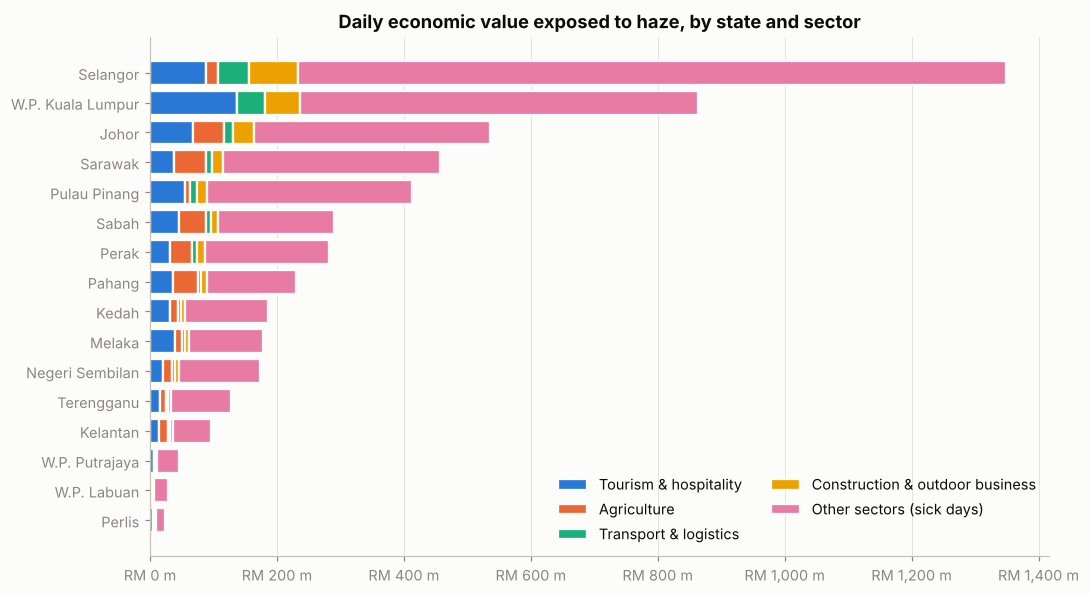

In [7]:
order = dev.sum(axis=1).sort_values().index
fig, ax = plt.subplots(figsize=(10, 5.5))
left = np.zeros(len(order))
for i, c in enumerate(dev.columns):
    ax.barh(order, dev.loc[order, c], left=left, color=SERIES[i], edgecolor="#fcfcfb", lw=1.5, label=c)
    left += dev.loc[order, c].to_numpy()
ax.xaxis.set_major_formatter(rm_m); ax.grid(axis="y", visible=False)
ax.set_title("Daily economic value exposed to haze, by state and sector")
ax.legend(ncol=2, loc="lower right"); plt.tight_layout(); plt.show()

## 4. Loss rates by haze severity (brief steps 4–5)
Share of each sector's daily activity lost on a day in each API band (low / central / high).
Low and high drive the best/worst scenarios and the Monte Carlo range. Sources are listed under the table.

In [8]:
lr = pd.DataFrame({SECTORS[s]: {b.replace("_", " "): f"{r[b][1]:.1%}  ({r[b][0]:.1%}–{r[b][2]:.1%})"
                                for b in policy.BANDS[1:]} for s, r in policy.LOSS_RATES.items()}).T
display(lr)
for s, r in policy.LOSS_RATES.items():
    print(f"• {SECTORS[s]}: {r['source']}")

,moderate,unhealthy,very unhealthy,hazardous
Tourism & hospitality,0.5% (0.0%–1.0%),6.0% (3.0%–10.0%),12.0% (6.0%–20.0%),25.0% (12.0%–40.0%)
Agriculture,0.0% (0.0%–0.0%),1.0% (0.5%–2.0%),2.5% (1.0%–5.0%),5.0% (3.0%–10.0%)
Transport & logistics,0.0% (0.0%–0.0%),0.5% (0.0%–1.0%),2.0% (1.0%–4.0%),6.0% (3.0%–10.0%)
Construction & outdoor business,0.0% (0.0%–0.0%),3.0% (1.0%–5.0%),12.0% (5.0%–20.0%),35.0% (20.0%–50.0%)
Other sectors (sick days),0.0% (0.0%–0.0%),0.2% (0.1%–0.4%),1.0% (0.5%–2.0%),2.5% (1.0%–4.0%)


• Tourism & hospitality: Arrivals down up to 8% in the 2026 haze (Yeah Kim Leng, The Star, 14 Oct 2026); cancellations and event postponements at API > 150 (Borneo Post, 31 Aug 2026)
• Agriculture: Reduced sunlight cuts photosynthesis; analysts warned of a 10–20% oil-palm output fall after the prolonged 2015 haze (The Star, 18 Sep 2015). Daily rates kept well below that
• Transport & logistics: APPROX — check: flight delays and port/road visibility limits mostly above API 200
• Construction & outdoor business: MOH advice: minimise strenuous outdoor work at API 101–200, avoid it at 201–300 (Borneo Post, 31 Aug 2026)
• Other sectors (sick days): Medical leave ~RM 203 m in the 2013 haze (MJPHM review); applied only to sectors not listed above


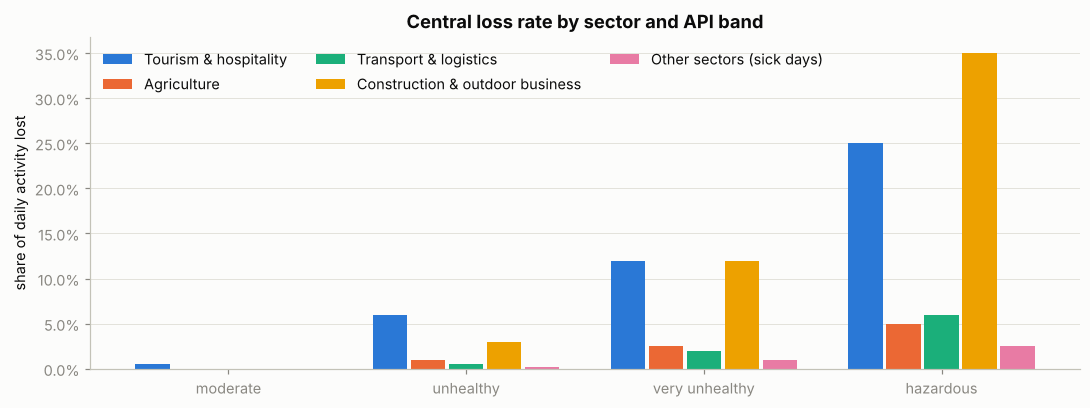

PASS  Loss rates never fall as haze gets worse
PASS  Low ≤ central ≤ high for every rate
PASS  Every sector's loss rate has a source
PASS  Worked example: RM 10 m/day × 5% × 3 days = RM 1.5 m  —  RM 1.50 m


True

In [9]:
fig, ax = plt.subplots(figsize=(10, 3.8))
bands_ = policy.BANDS[1:]
w = 0.8 / len(policy.LOSS_RATES)
x = np.arange(len(bands_))
for i, (s, r) in enumerate(policy.LOSS_RATES.items()):
    ax.bar(x + i * w - 0.4 + w / 2, [r[b][1] for b in bands_], width=w * 0.9, color=SERIES[i], label=SECTORS[s])
ax.set_xticks(x, [b.replace("_", " ") for b in bands_]); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_ylabel("share of daily activity lost"); ax.grid(axis="x", visible=False)
ax.set_title("Central loss rate by sector and API band"); ax.legend(ncol=3, loc="upper left"); plt.tight_layout(); plt.show()

rates_c = policy.rate_table("central")
check("Loss rates never fall as haze gets worse",
      all(np.all(np.diff([rates_c[s][b] for b in policy.BANDS]) >= 0) for s in rates_c))
check("Low ≤ central ≤ high for every rate",
      all(r[b][0] <= r[b][1] <= r[b][2] for r in policy.LOSS_RATES.values() for b in bands_))
check("Every sector's loss rate has a source", all(r["source"].strip() for r in policy.LOSS_RATES.values()))
check("Worked example: RM 10 m/day × 5% × 3 days = RM 1.5 m",
      abs(policy.damage_cost(10e6, 0.05, 3) - 1.5e6) < 1e-6, f"RM {policy.damage_cost(10e6, 0.05, 3)/1e6:.2f} m")

## 5. Haze data checks

In [10]:
dates = pd.to_datetime(haze.date)
check("All 16 states in the state table", set(ref.state) == set(policy.STATE_NAMES), f"{ref.state.nunique()} states")
check("All 16 states in the haze table", set(haze.state) == set(policy.STATE_NAMES))
check("No missing values (state table)", not ref.isna().any().any())
check("No missing values (haze table)", not haze.isna().any().any())
check("One row per state per day", not haze.duplicated(["state", "date"]).any())
check("No gaps in the dates", haze.groupby("state").date.nunique().eq(dates.dt.normalize().nunique()).all(),
      f"{dates.min():%d %b} → {dates.max():%d %b %Y}")
check("PM2.5 within 0–500 µg/m3", haze.pm25_ugm3.between(0, 500).all(),
      f"max {haze.pm25_ugm3.max():.0f}")
check("API within 0–500", haze.api_max.between(0, 500).all())
check("Worst station API ≥ state average API", (haze.api_max >= haze.api_mean - 0.1).all())
check("School-closure share within 0–1", haze.school_closed_share.between(0, 1).all())
check("Sarawak has the worst peak (as in the real 2026 data)",
      haze.groupby("state").pm25_ugm3.max().idxmax() == "Sarawak")

PASS  All 16 states in the state table  —  16 states
PASS  All 16 states in the haze table
PASS  No missing values (state table)
PASS  No missing values (haze table)
PASS  One row per state per day
PASS  No gaps in the dates  —  15 Aug → 16 Oct 2026
PASS  PM2.5 within 0–500 µg/m3  —  max 196
PASS  API within 0–500
PASS  Worst station API ≥ state average API
PASS  School-closure share within 0–1
PASS  Sarawak has the worst peak (as in the real 2026 data)


True

### PM2.5 over time
Sarawak (Borneo wave, late Aug) and the Klang Valley (west-coast wave, mid-Oct) highlighted; other states in grey.

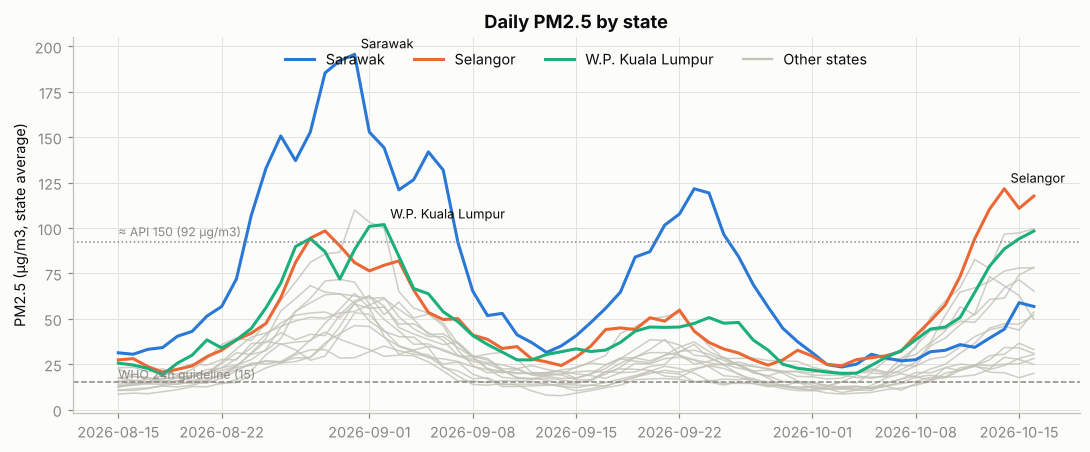

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.2))
highlight = {"Sarawak": SERIES[0], "Selangor": SERIES[1], "W.P. Kuala Lumpur": SERIES[2]}
h = haze.assign(date=pd.to_datetime(haze.date))
for s, g in h.groupby("state"):
    if s not in highlight:
        ax.plot(g.date, g.pm25_ugm3, color=OTHER, lw=1, alpha=0.8)
for s, col in highlight.items():
    g = h[h.state == s]
    ax.plot(g.date, g.pm25_ugm3, color=col, lw=2, label=s)
    i = g.pm25_ugm3.idxmax()
    ax.annotate(s, (g.date[i], g.pm25_ugm3[i]), xytext=(4, 4), textcoords="offset points", color=INK, fontsize=8.5)
ax.axhline(15, color=MUTED, lw=1, ls="--"); ax.text(h.date.min(), 17, "WHO 24h guideline (15)", color=MUTED, fontsize=8)
pm150 = float(policy.api_to_pm25(150))
ax.axhline(pm150, color=MUTED, lw=1, ls=":"); ax.text(h.date.min(), pm150 + 3, f"≈ API 150 ({pm150:.0f} µg/m3)", color=MUTED, fontsize=8)
ax.set_title("Daily PM2.5 by state"); ax.set_ylabel("PM2.5 (µg/m3, state average)")
ax.plot([], [], color=OTHER, label="Other states"); ax.legend(loc="upper center", ncol=4)
plt.tight_layout(); plt.show()

### Days in each API band (worst station in the state)

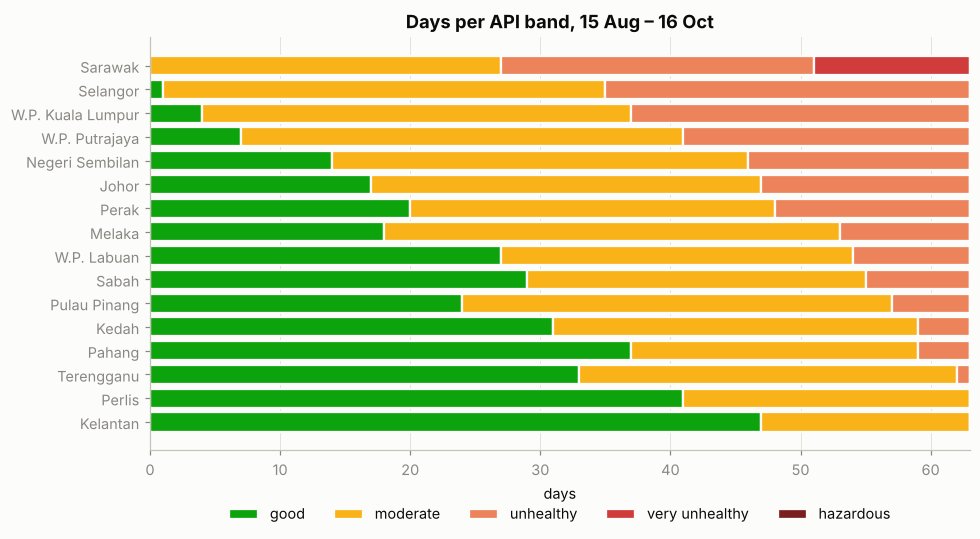

In [12]:
bands = list(BAND_COLOURS)
counts = pd.crosstab(haze.state, haze.api_band).reindex(columns=bands, fill_value=0)
counts = counts.loc[counts[["unhealthy", "very_unhealthy", "hazardous"]].sum(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(9, 5))
left = np.zeros(len(counts))
for b in bands:
    ax.barh(counts.index, counts[b], left=left, color=BAND_COLOURS[b], edgecolor="#fcfcfb", lw=1.5,
            label=b.replace("_", " "))
    left += counts[b].to_numpy()
ax.set_xlabel("days"); ax.set_title("Days per API band, 15 Aug – 16 Oct"); ax.grid(axis="y", visible=False)
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.tight_layout(); plt.show()

### Mock vs real PM2.5
Only runs if the real Open-Meteo file is in the repo (`data/raw/pm25_daily_openmeteo.csv`, from the Resource Allocation branch).

In [13]:
real, real_path = policy.load_real_pm25()
if real is None:
    print("Real PM2.5 file not found — skipping. Copy pm25_daily_openmeteo.csv into data/raw/ to enable.")
else:
    r = real[real.date >= "2026-08-15"].groupby("state").pm25.agg(["max", "mean"])
    m = mock["haze_daily"].query("date <= @real.date.max()").groupby("state").pm25_ugm3.agg(["max", "mean"])
    cmp_ = r.join(m, lsuffix="_real", rsuffix="_mock").sort_values("max_real")
    fig, ax = plt.subplots(figsize=(8, 5))
    y = np.arange(len(cmp_))
    ax.barh(y + 0.2, cmp_.max_real, height=0.4, color=SERIES[0], label="real (Open-Meteo)")
    ax.barh(y - 0.2, cmp_.max_mock, height=0.4, color=SERIES[1], label="mock")
    ax.set_yticks(y, cmp_.index); ax.set_xlabel("peak PM2.5 (µg/m3)"); ax.legend()
    ax.set_title(f"Peak PM2.5, 15 Aug – {real.date.max()}"); plt.tight_layout(); plt.show()
    corr = np.corrcoef(cmp_.max_real, cmp_.max_mock)[0, 1]
    check("Mock peaks track real peaks (r > 0.8)", corr > 0.8, f"r = {corr:.2f}")

Real PM2.5 file not found — skipping. Copy pm25_daily_openmeteo.csv into data/raw/ to enable.


## 6. Run the damage model

In [14]:
N_SIMS = 1000
result = policy.run(n_sims=N_SIMS, write=False, fetch=FETCH_OPENDOSM)
nat = result["national"]
print(f"Episode: {result['episode']['start']} → {result['episode']['end']} ({result['episode']['days']} days)")
print(f"National damage: RM {nat['total_damage_rm']/1e9:.2f} bn  "
      f"(90% range RM {nat['ci90_rm'][0]/1e9:.2f}–{nat['ci90_rm'][1]/1e9:.2f} bn)")
print(f"Per day (episode average): RM {nat['damage_per_day_rm']/1e6:.0f} m")
print("Not added to the total (overlap):", {k: f"RM {v/1e6:,.1f} m" for k, v in nat["memo_not_in_total_rm"].items()})
pd.DataFrame([{"state": s["state"], "damage_rm_m": s["damage_to_date_rm"] / 1e6, "pct_gdp": s["damage_pct_gdp"],
               **{f"forecast_{h}h_rm_m": v / 1e6 for h, v in s["forecast_damage_rm"].items()}}
              for s in result["states"]]).round(2)

[info] OpenDOSM gdp_state_real_supply unavailable (URLError); using built-in 2025 values


Episode: 2026-08-15 → 2026-10-16 (63 days)
National damage: RM 0.95 bn  (90% range RM 0.55–1.38 bn)
Per day (episode average): RM 15 m
Not added to the total (overlap): {'school_closure': 'RM 161.7 m', 'response': 'RM 0.8 m', 'mortality': 'RM 0.0 m'}


,state,damage_rm_m,pct_gdp,forecast_24h_rm_m,forecast_48h_rm_m,forecast_72h_rm_m
0,W.P. Kuala Lumpur,246.34,0.09,11.45,11.45,11.45
1,Selangor,227.71,0.05,10.64,10.64,10.64
2,Sarawak,219.85,0.14,1.86,1.86,1.86
3,Johor,71.08,0.04,5.56,5.56,5.56
4,Perak,35.20,0.04,1.90,1.90,1.90
5,Sabah,32.26,0.04,0.25,0.25,0.25
6,Melaka,29.11,0.06,2.37,2.37,2.37
7,Negeri Sembilan,24.53,0.04,1.86,1.86,1.86
8,Pulau Pinang,23.41,0.02,1.49,1.49,1.49
9,W.P. Putrajaya,11.52,0.08,0.56,0.56,0.56


## 7. Output checks

In [15]:
states = result["states"]
cats = policy.CATEGORIES
state_keys = {"state", "lat", "lon", "population", "damage_to_date_rm", "by_category_rm",
              "damage_pct_gdp", "forecast_damage_rm", "api_latest"}
check("Top-level fields present", {"episode", "national", "states", "model", "assumptions"} <= set(result))
check("Every state has every field", all(state_keys <= set(s) for s in states))
check("16 states in the output", len(states) == 16)
check(f"Every state has all {len(cats)} sectors", all(set(s["by_category_rm"]) == set(cats) for s in states))
check("Memo items kept out of the total (no double counting)",
      all(not set(s["memo_not_in_total_rm"]) & set(s["by_category_rm"]) for s in states))
check("No negative costs", all(v >= 0 for s in states for v in s["by_category_rm"].values()))
check("Categories add up to each state's total",
      all(abs(sum(s["by_category_rm"].values()) - s["damage_to_date_rm"]) <= len(cats) for s in states))
check("States add up to the national total",
      abs(sum(s["damage_to_date_rm"] for s in states) - nat["total_damage_rm"]) <= len(states))
check("National total inside its 90% range", nat["ci90_rm"][0] <= nat["total_damage_rm"] <= nat["ci90_rm"][1])
check("Forecast has 24/48/72h for every state", all(set(s["forecast_damage_rm"]) == {"24", "48", "72"} for s in states))
check("Every assumption has a source", all(str(a["source"]).strip() for a in result["assumptions"]))
dummy = {k for k, v in policy.COEFFS.items() if "DUMMY" in v["source"]}
flagged = {a["name"] for a in result["assumptions"] if "DUMMY" in str(a["source"])}
check("Dummy values are labelled as dummy", dummy <= flagged, f"{len(dummy)} coefficients still dummy")
check("Mortality excluded (haze treated as non-fatal)", nat["memo_not_in_total_rm"]["mortality"] == 0)
check("Backtest scores filled in", result["model"]["backtest_mape"] is not None)
if policy.STATES_JSON.exists():
    import json
    theirs = {s["state"] for s in json.loads(policy.STATES_JSON.read_text())["states"]}
    check("State names match Resource Allocation's states.json", theirs == set(policy.STATE_NAMES))
else:
    print("SKIP  states.json not in data/out yet")

PASS  Top-level fields present
PASS  Every state has every field
PASS  16 states in the output
PASS  Every state has all 6 sectors
PASS  Memo items kept out of the total (no double counting)
PASS  No negative costs
PASS  Categories add up to each state's total
PASS  States add up to the national total
PASS  National total inside its 90% range
PASS  Forecast has 24/48/72h for every state
PASS  Every assumption has a source
PASS  Dummy values are labelled as dummy  —  9 coefficients still dummy
PASS  Mortality excluded (haze treated as non-fatal)
PASS  Backtest scores filled in
SKIP  states.json not in data/out yet


## 8. Results by sector and state (brief step 6)

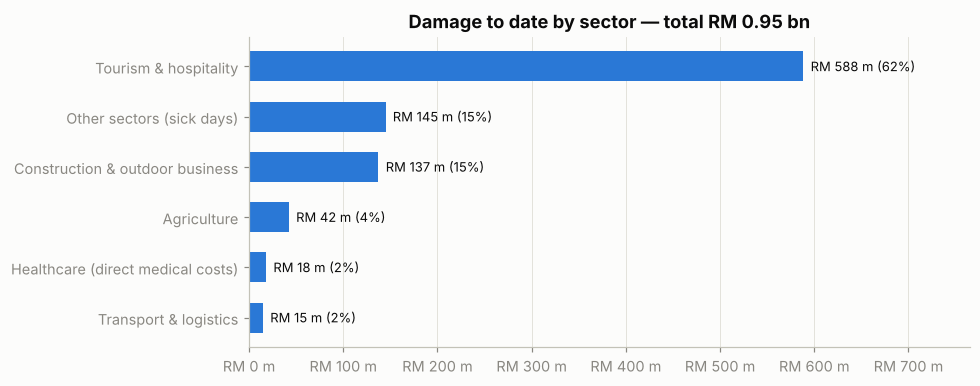

In [16]:
# National damage by sector
by_sec = pd.Series({SECTORS[k]: v for k, v in nat["by_category_rm"].items()}).sort_values()
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(by_sec.index, by_sec.values, color=SERIES[0], height=0.6)
for y, v in enumerate(by_sec.values):
    ax.text(v, y, f"  RM {v/1e6:,.0f} m ({v/by_sec.sum():.0%})", va="center", fontsize=8.5)
ax.xaxis.set_major_formatter(rm_m); ax.grid(axis="y", visible=False); ax.set_xlim(0, by_sec.max() * 1.3)
ax.set_title(f"Damage to date by sector — total RM {by_sec.sum()/1e9:.2f} bn"); plt.tight_layout(); plt.show()

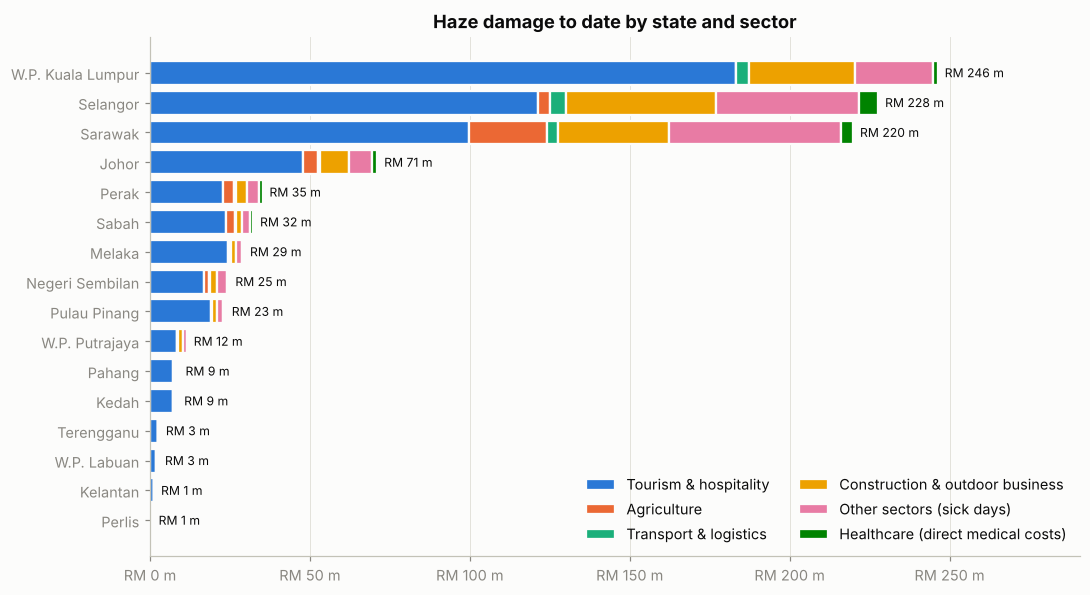

In [17]:
# Damage by state, stacked by sector
show = [c for c in cats if nat["by_category_rm"][c] > 0]
df = pd.DataFrame([{**s["by_category_rm"], "state": s["state"]} for s in states]).set_index("state")[show]
df = df.loc[df.sum(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(10, 5.5))
left = np.zeros(len(df))
for i, c in enumerate(show):
    ax.barh(df.index, df[c], left=left, color=SERIES[i], edgecolor="#fcfcfb", lw=1.5, label=SECTORS[c])
    left += df[c].to_numpy()
for y, v in enumerate(left):
    ax.text(v, y, f"  RM {v/1e6:,.0f} m", va="center", fontsize=8, color=INK)
ax.xaxis.set_major_formatter(rm_m); ax.grid(axis="y", visible=False)
ax.set_title("Haze damage to date by state and sector")
ax.legend(ncol=2, loc="lower right")
ax.set_xlim(0, left.max() * 1.18); plt.tight_layout(); plt.show()

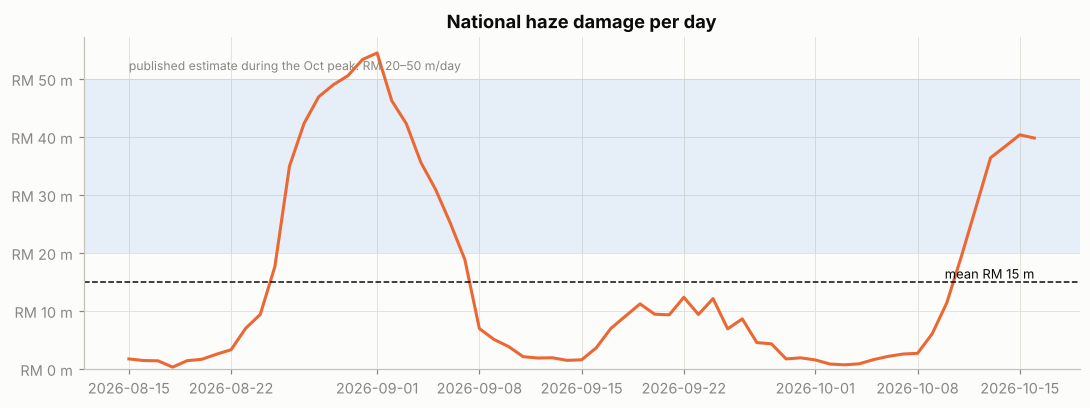

In [18]:
# National damage per day vs the published RM 20–50 m/day estimate
daily = policy.damage_by_day(haze, ref, policy.central())
nd = daily.groupby("date").total_damage_rm.sum()
nd.index = pd.to_datetime(nd.index)
lo, hi = result["model"]["benchmark_rm_per_day"]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.axhspan(lo, hi, color=SERIES[0], alpha=0.10, lw=0)
ax.text(nd.index.min(), hi * 1.03, "published estimate during the Oct peak: RM 20–50 m/day", color=MUTED, fontsize=8)
ax.plot(nd.index, nd.values, color=SERIES[1], lw=2)
ax.axhline(nd.mean(), color=INK, lw=1, ls="--")
ax.text(nd.index.max(), nd.mean(), f" mean RM {nd.mean()/1e6:.0f} m", va="bottom", ha="right", fontsize=8.5)
ax.yaxis.set_major_formatter(rm_m); ax.set_title("National haze damage per day"); ax.set_ylim(0)
plt.tight_layout(); plt.show()

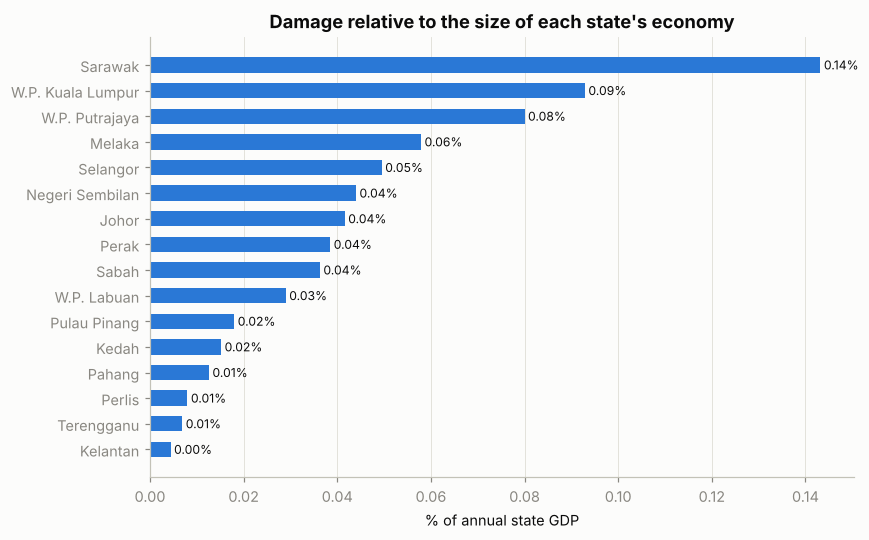

In [19]:
# Damage as % of each state's annual GDP
pct = pd.Series({s["state"]: s["damage_pct_gdp"] for s in states}).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(pct.index, pct.values, color=SERIES[0], height=0.6)
for y, v in enumerate(pct.values):
    ax.text(v, y, f" {v:.2f}%", va="center", fontsize=8)
ax.set_xlabel("% of annual state GDP"); ax.grid(axis="y", visible=False)
ax.set_title("Damage relative to the size of each state's economy"); plt.tight_layout(); plt.show()

## 9. Next 72 hours — best / expected / worst (brief step 7)
| Scenario | Haze | Loss rates | Share of activity affected | Duration |
|---|---|---|---|---|
| Best | forecast PM2.5 × 0.75 | low | × 0.75 | clears after 2 days |
| Expected | forecast PM2.5 | central | as forecast | 3 days |
| Worst | forecast PM2.5 × 1.35 | high | × 1.25 | 3 days, + 4 more if it persists |

Forecast input: persistence (mean of last 3 days) — forecast.json not found


,Best,Expected,Worst
Tourism & hospitality,RM 12.1 m,RM 74.9 m,RM 190.6 m
Agriculture,RM 0.4 m,RM 4.0 m,RM 14.6 m
Transport & logistics,RM 0.0 m,RM 2.0 m,RM 10.9 m
Construction & outdoor business,RM 1.9 m,RM 18.1 m,RM 89.4 m
Other sectors (sick days),RM 3.0 m,RM 16.5 m,RM 99.4 m
Healthcare (direct medical costs),RM 0.2 m,RM 2.0 m,RM 9.8 m
TOTAL (72 h),RM 17.6 m,RM 117.4 m,RM 414.7 m
if prolonged,RM 17.6 m,RM 117.4 m,RM 967.6 m


PASS  Best ≤ expected ≤ worst
PASS  Scenario sectors add up to each scenario's total
PASS  Prolonged worst case ≥ its 72-hour total


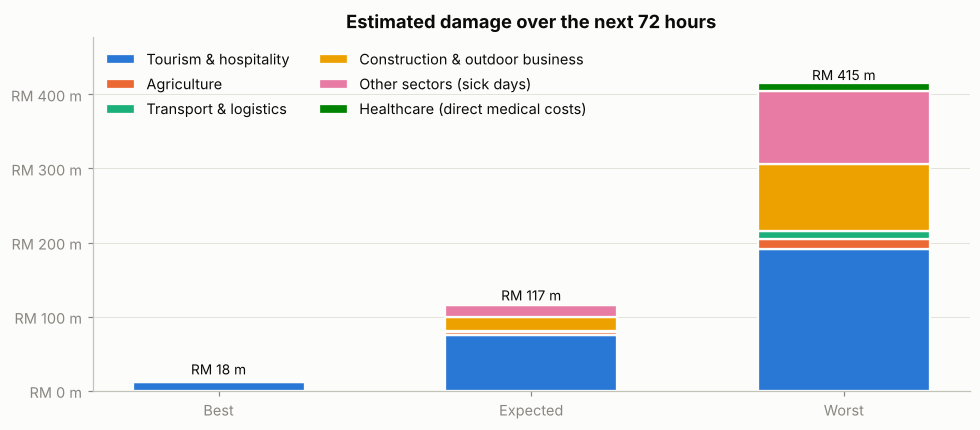

In [20]:
sc = result["forecast_72h"]["scenarios"]
print("Forecast input:", result["forecast_72h"]["source"])
tbl = pd.DataFrame({n: {**{SECTORS[k]: v / 1e6 for k, v in d["by_sector_rm"].items()},
                        "TOTAL (72 h)": d["total_72h_rm"] / 1e6,
                        "if prolonged": d["if_prolonged_rm"] / 1e6} for n, d in sc.items()}).round(1)
display(tbl.rename(columns=str.title).style.format("RM {:,.1f} m"))
check("Best ≤ expected ≤ worst", sc["best"]["total_72h_rm"] <= sc["expected"]["total_72h_rm"] <= sc["worst"]["total_72h_rm"])
check("Scenario sectors add up to each scenario's total",
      all(abs(sum(d["by_sector_rm"].values()) - d["total_72h_rm"]) < 10 for d in sc.values()))
check("Prolonged worst case ≥ its 72-hour total", sc["worst"]["if_prolonged_rm"] >= sc["worst"]["total_72h_rm"])

fig, ax = plt.subplots(figsize=(9, 4))
names = list(sc)
bottom = np.zeros(len(names))
for i, k in enumerate(cats):
    vals = np.array([sc[n]["by_sector_rm"][k] for n in names])
    ax.bar([n.title() for n in names], vals, bottom=bottom, color=SERIES[i], edgecolor="#fcfcfb", lw=1.5,
           label=SECTORS[k], width=0.55)
    bottom += vals
for x, v in enumerate(bottom):
    ax.text(x, v, f"RM {v/1e6:,.0f} m", ha="center", va="bottom", fontsize=9)
ax.yaxis.set_major_formatter(rm_m); ax.grid(axis="x", visible=False); ax.set_ylim(0, bottom.max() * 1.15)
ax.set_title("Estimated damage over the next 72 hours"); ax.legend(ncol=2, loc="upper left"); plt.tight_layout(); plt.show()

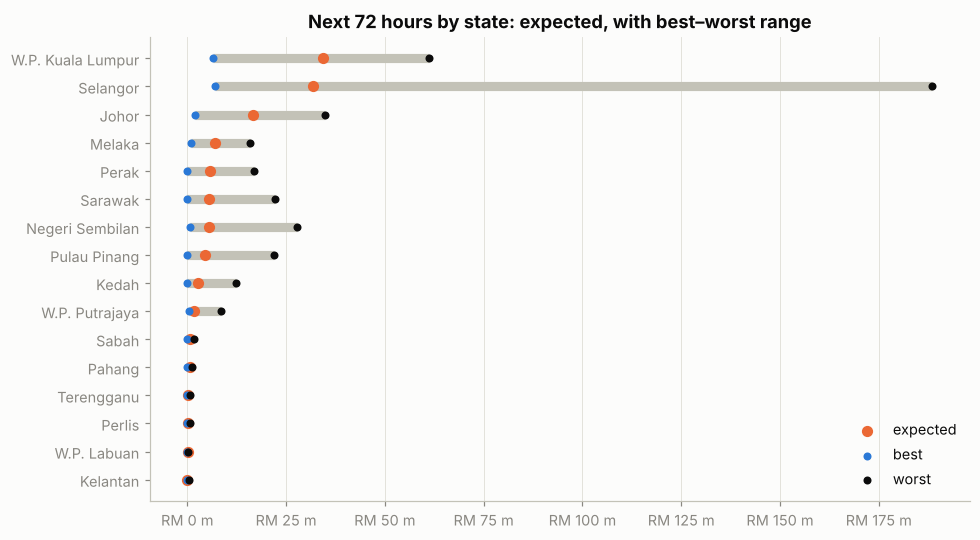

In [21]:
# 72-hour expected damage by state, with the best–worst range
st = pd.DataFrame({n: sc[n]["by_state_rm"] for n in sc}).sort_values("expected")
st = st[st.worst > 0]
fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(st))
ax.hlines(y, st.best, st.worst, color=OTHER, lw=6)
ax.scatter(st.expected, y, color=SERIES[1], s=40, zorder=3, label="expected")
ax.scatter(st.best, y, color=SERIES[0], s=18, zorder=3, label="best")
ax.scatter(st.worst, y, color=INK, s=18, zorder=3, label="worst")
ax.set_yticks(y, st.index); ax.xaxis.set_major_formatter(rm_m); ax.grid(axis="y", visible=False)
ax.set_title("Next 72 hours by state: expected, with best–worst range"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

## 10. Behaviour checks

PASS  Clean air (PM2.5 10, API ~40) costs nothing  —  RM 0


PASS  Damage never falls as PM2.5 rises
PASS  Damage rises between clean and unhealthy air
PASS  Health cost rises smoothly with PM2.5


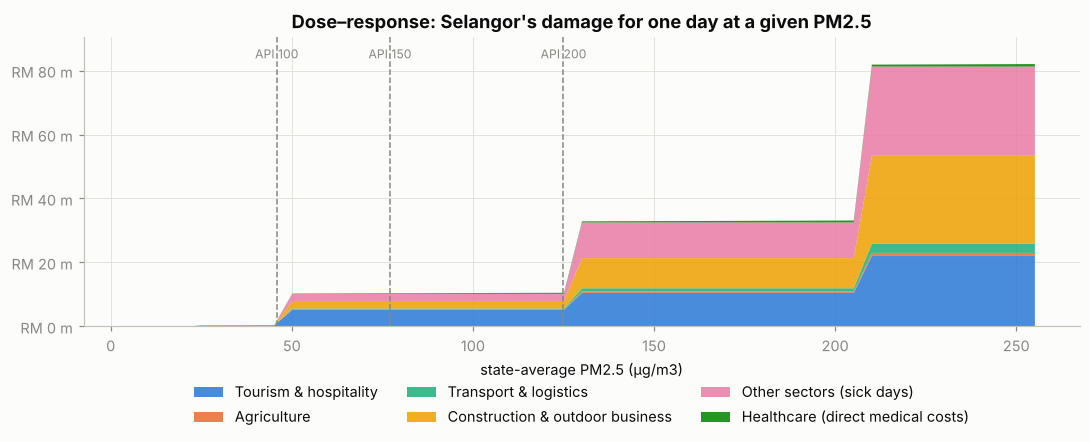

Steps = API band thresholds where each sector's loss rate changes; healthcare rises smoothly with PM2.5.


In [22]:
def one_day(pm25, state=None):
    """One synthetic day at a fixed PM2.5 for every state (or one state)."""
    api_avg = float(policy.pm25_to_api(pm25)); api_worst = float(policy.pm25_to_api(pm25 * 1.2))
    d = pd.DataFrame({"date": "2026-01-01", "state": ref.state, "pm25_ugm3": pm25, "api_mean": api_avg,
                      "api_max": api_worst, "affected_share": 1.0, "school_closed_share": 0.5 if api_worst > 200 else 0.0,
                      "school_closed": int(api_worst > 200), "flights_disrupted": 0, "cloud_seeding_ops": 0})
    return d if state is None else d[d.state == state]

c0 = policy.central()
clean = policy.damage_by_day(one_day(10), ref, c0).total_damage_rm.sum()
check("Clean air (PM2.5 10, API ~40) costs nothing", abs(clean) < 1, f"RM {clean:,.0f}")

grid = np.arange(5, 260, 5)
curve = pd.DataFrame([policy.damage_by_day(one_day(p, "Selangor"), ref, c0)[cats].sum() for p in grid], index=grid)
total = curve.sum(axis=1)
check("Damage never falls as PM2.5 rises", (np.diff(total.to_numpy()) >= -1).all())
check("Damage rises between clean and unhealthy air", total.loc[100] > total.loc[20] > total.loc[5])
check("Health cost rises smoothly with PM2.5", (np.diff(curve.health.to_numpy()) > 0)[2:].all())

fig, ax = plt.subplots(figsize=(10, 4.2))
bottom = np.zeros(len(grid))
for i, c in enumerate([c for c in cats if curve[c].max() > 0]):
    ax.fill_between(grid, bottom, bottom + curve[c], color=SERIES[i], alpha=0.85, lw=0, label=SECTORS[c])
    bottom += curve[c].to_numpy()
for a in (100, 150, 200):
    x = float(policy.api_to_pm25(a) / 1.2)   # state average at which the worst station typically reaches API a
    ax.axvline(x, color=MUTED, lw=1, ls="--"); ax.text(x, bottom.max() * 1.02, f"API {a}", color=MUTED, fontsize=8, ha="center")
ax.yaxis.set_major_formatter(rm_m); ax.set_xlabel("state-average PM2.5 (µg/m3)")
ax.set_title("Dose–response: Selangor's damage for one day at a given PM2.5")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.15)); ax.set_ylim(0, bottom.max() * 1.1)
plt.tight_layout(); plt.show()
print("Steps = API band thresholds where each sector's loss rate changes; healthcare rises smoothly with PM2.5.")

## 11. Uncertainty (Monte Carlo)

PASS  90% range is not absurdly wide (95th < 3× 5th)  —  RM 0.55–1.38 bn


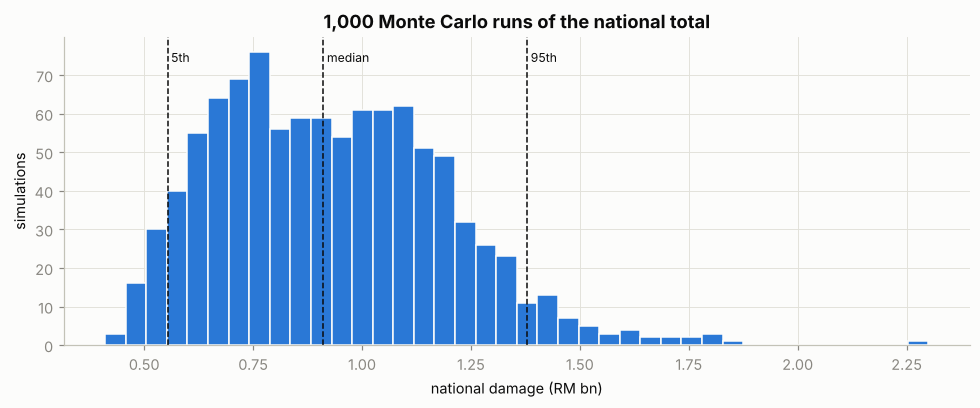

In [23]:
draws = policy.monte_carlo(haze, ref, N_SIMS).sum(axis=1)
p5, p50, p95 = np.percentile(draws, [5, 50, 95])
check("90% range is not absurdly wide (95th < 3× 5th)", p95 < 3 * p5, f"RM {p5/1e9:.2f}–{p95/1e9:.2f} bn")
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(draws / 1e9, bins=40, color=SERIES[0], edgecolor="#fcfcfb", lw=1)
for v, lab in [(p5, "5th"), (p50, "median"), (p95, "95th")]:
    ax.axvline(v / 1e9, color=INK, lw=1, ls="--"); ax.text(v / 1e9, ax.get_ylim()[1] * 0.92, f" {lab}", fontsize=8)
ax.set_xlabel("national damage (RM bn)"); ax.set_ylabel("simulations")
ax.set_title(f"{N_SIMS:,} Monte Carlo runs of the national total"); plt.tight_layout(); plt.show()

## 12. Sensitivity — which assumptions matter most

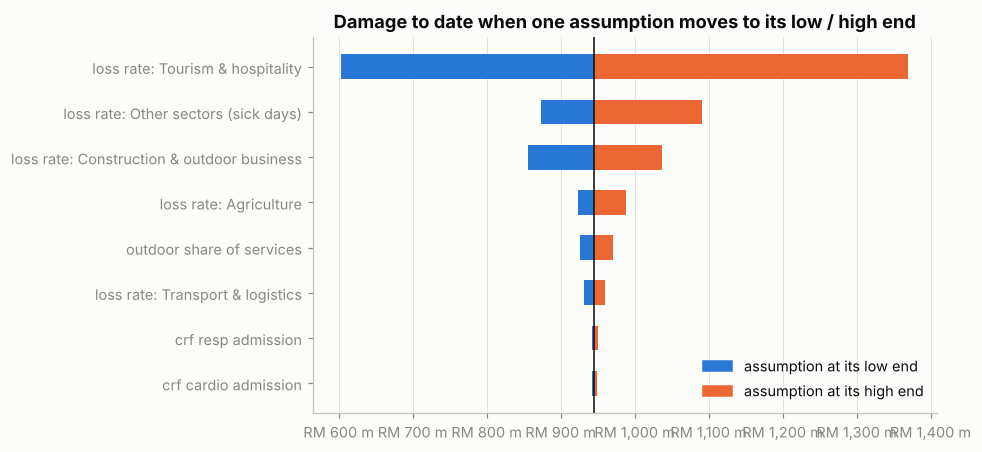

,coefficient,swing_rm_m
0,loss rate: Tourism & hospitality,767.0
1,loss rate: Other sectors (sick days),217.0
2,loss rate: Construction & outdoor business,181.0
3,loss rate: Agriculture,65.0
4,outdoor_share_of_services,44.0
5,loss rate: Transport & logistics,28.0
6,crf_resp_admission,8.0
7,crf_cardio_admission,7.0


In [24]:
tor = policy.sensitivity(haze, ref, top=8).iloc[::-1]
base = nat["total_damage_rm"]
fig, ax = plt.subplots(figsize=(9, 4.2))
for y, r in enumerate(tor.itertuples()):
    lo_, hi_ = sorted([r.low_rm, r.high_rm])
    ax.barh(y, lo_ - base, left=base, color=SERIES[0], height=0.55)
    ax.barh(y, hi_ - base, left=base, color=SERIES[1], height=0.55)
ax.axvline(base, color=INK, lw=1)
ax.set_yticks(range(len(tor)), tor.coefficient.str.replace("_", " ")); ax.xaxis.set_major_formatter(rm_m)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=SERIES[0], label="assumption at its low end"),
                   Patch(color=SERIES[1], label="assumption at its high end")], loc="lower right"); ax.grid(axis="y", visible=False)
ax.set_title("Damage to date when one assumption moves to its low / high end"); plt.tight_layout(); plt.show()
tor.iloc[::-1].assign(swing_rm_m=lambda d: (d.swing_rm / 1e6).round(0))[["coefficient", "swing_rm_m"]]

## 13. Backtest vs mock truth
⚠️ The mock "truth" was generated with the same formulas (plus noise), so a low error here only shows the code
is consistent — it is **not** evidence the model is right. Section 14 is the real sanity check.

PASS  Damage function beats the PM2.5-only baseline  —  MAPE 2.0% vs baseline 438.0%


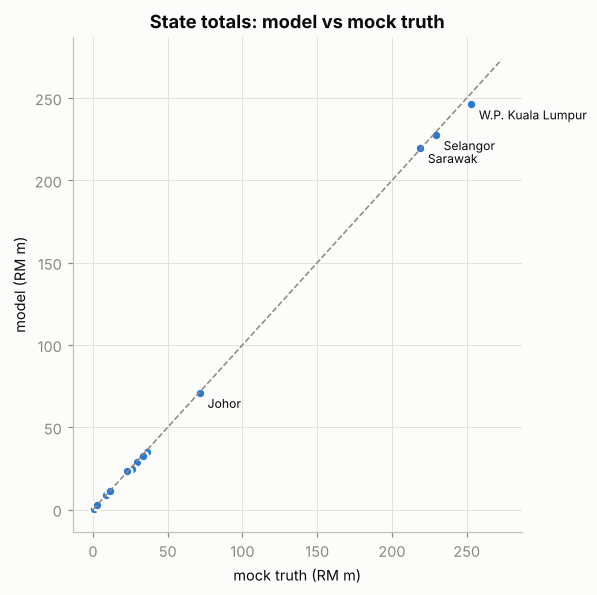

In [25]:
m_haze, m_ref, m_truth = mock["haze_daily"], mock["state_reference"], mock["damage_costs_daily"]
pred = policy.damage_by_day(m_haze, m_ref, c0).groupby("state").total_damage_rm.sum()
act = m_truth.groupby("state").total_damage_rm.sum()
bt = result["model"]
check("Damage function beats the PM2.5-only baseline", bt["backtest_mape"] < bt["baseline_mape"],
      f"MAPE {bt['backtest_mape']:.1%} vs baseline {bt['baseline_mape']:.1%}")
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(act / 1e6, pred.reindex(act.index) / 1e6, s=40, color=SERIES[0], edgecolor="#fcfcfb", lw=1.5)
lim = max(act.max(), pred.max()) / 1e6 * 1.08
ax.plot([0, lim], [0, lim], color=MUTED, lw=1, ls="--")
for s in act.nlargest(4).index:
    ax.annotate(s, (act[s] / 1e6, pred[s] / 1e6), xytext=(5, -10), textcoords="offset points", fontsize=8)
ax.set_xlabel("mock truth (RM m)"); ax.set_ylabel("model (RM m)")
ax.set_title("State totals: model vs mock truth"); plt.tight_layout(); plt.show()

## 14. Realism check vs published estimates
The RM 20–50 m/day estimate was made on 14 Oct, during the October peak, so it's compared with the
*expected* 72-hour forecast (which starts from current conditions), not the episode average.

PASS  Current expected damage within the published RM 20–50 m/day  —  RM 39 m/day
PASS  Episode average not far below the published range (≥ half of RM 20 m/day)  —  RM 15 m/day
PASS  Same order of magnitude as the 2013 haze (0.3×–3×)  —  0.6× 2013
PASS  Health costs don't dominate (haze mostly costs the economy)


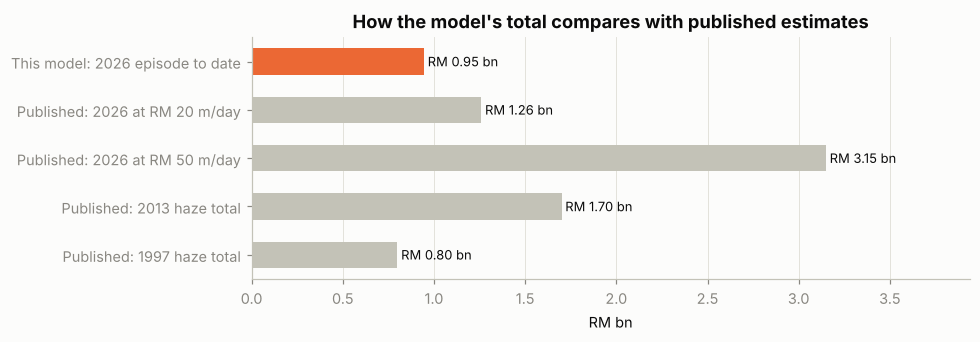

Sources: The Star, 14 Oct 2026 (Yeah Kim Leng); MJPHM literature review (2013 haze).


In [26]:
B = policy.BENCHMARKS
days = result["episode"]["days"]
exp_per_day = sc["expected"]["total_72h_rm"] / 3
rows = [
    ("This model: 2026 episode to date", nat["total_damage_rm"]),
    ("Published: 2026 at RM 20 m/day", B["2026_daily_low_rm"] * days),
    ("Published: 2026 at RM 50 m/day", B["2026_daily_high_rm"] * days),
    ("Published: 2013 haze total", B["2013_total_rm"]),
    ("Published: 1997 haze total", B["1997_total_rm"]),
]
bench = pd.DataFrame(rows, columns=["estimate", "rm"]).set_index("estimate")
check("Current expected damage within the published RM 20–50 m/day",
      B["2026_daily_low_rm"] <= exp_per_day <= B["2026_daily_high_rm"], f"RM {exp_per_day/1e6:.0f} m/day")
check("Episode average not far below the published range (≥ half of RM 20 m/day)",
      nat["damage_per_day_rm"] >= B["2026_daily_low_rm"] / 2, f"RM {nat['damage_per_day_rm']/1e6:.0f} m/day")
check("Same order of magnitude as the 2013 haze (0.3×–3×)",
      0.3 <= nat["total_damage_rm"] / B["2013_total_rm"] <= 3, f"{nat['total_damage_rm']/B['2013_total_rm']:.1f}× 2013")
check("Health costs don't dominate (haze mostly costs the economy)",
      nat["by_category_rm"]["health"] < 0.25 * nat["total_damage_rm"])
fig, ax = plt.subplots(figsize=(9, 3.2))
cols = [SERIES[1]] + [OTHER] * (len(bench) - 1)
ax.barh(bench.index[::-1], bench.rm[::-1] / 1e9, color=cols[::-1], height=0.55)
for y, v in enumerate(bench.rm[::-1] / 1e9):
    ax.text(v, y, f" RM {v:.2f} bn", va="center", fontsize=8.5)
ax.set_xlabel("RM bn"); ax.grid(axis="y", visible=False); ax.set_xlim(0, bench.rm.max() / 1e9 * 1.25)
ax.set_title("How the model's total compares with published estimates"); plt.tight_layout(); plt.show()
print("Sources: The Star, 14 Oct 2026 (Yeah Kim Leng); MJPHM literature review (2013 haze).")

## 15. Test summary

In [27]:
summary = pd.DataFrame(RESULTS)
n_fail = (summary.result == "FAIL").sum()
print(f"{len(summary) - n_fail} passed, {n_fail} failed")
display(summary.style.map(lambda v: "color:#d03b3b;font-weight:bold" if v == "FAIL" else "", subset=["result"]))
assert n_fail == 0, f"{n_fail} check(s) failed — see the table above"

45 passed, 0 failed


,test,result,detail
0,Every state has a daily value for every sector,PASS,
1,Sector values add up to no more than GDP + tourism spending,PASS,
2,State GDP matches DOSM 2025 (RM 1.74 tn minus ~RM 46 bn 'supranational'),PASS,"16 states sum to RM 1,694 bn"
3,Loss rates never fall as haze gets worse,PASS,
4,Low ≤ central ≤ high for every rate,PASS,
5,Every sector's loss rate has a source,PASS,
6,Worked example: RM 10 m/day × 5% × 3 days = RM 1.5 m,PASS,RM 1.50 m
7,All 16 states in the state table,PASS,16 states
8,All 16 states in the haze table,PASS,
9,No missing values (state table),PASS,
